Epoch: 0, Total Loss: 0.735190, PDE Loss: 0.000815, IC Loss: 0.697820, BC Loss: 0.036556
Epoch: 1000, Total Loss: 0.000752, PDE Loss: 0.000606, IC Loss: 0.000045, BC Loss: 0.000101
Epoch: 2000, Total Loss: 0.000120, PDE Loss: 0.000106, IC Loss: 0.000004, BC Loss: 0.000010
Epoch: 3000, Total Loss: 0.000069, PDE Loss: 0.000061, IC Loss: 0.000003, BC Loss: 0.000005
Epoch: 4000, Total Loss: 0.000048, PDE Loss: 0.000043, IC Loss: 0.000002, BC Loss: 0.000003
Epoch: 5000, Total Loss: 0.000036, PDE Loss: 0.000032, IC Loss: 0.000002, BC Loss: 0.000002
Epoch: 6000, Total Loss: 0.000028, PDE Loss: 0.000025, IC Loss: 0.000001, BC Loss: 0.000002
Epoch: 7000, Total Loss: 0.000023, PDE Loss: 0.000021, IC Loss: 0.000001, BC Loss: 0.000001
Epoch: 8000, Total Loss: 0.000061, PDE Loss: 0.000031, IC Loss: 0.000017, BC Loss: 0.000013
Epoch: 9000, Total Loss: 0.000022, PDE Loss: 0.000020, IC Loss: 0.000001, BC Loss: 0.000001

Maximum Error: 0.00042241625487804413


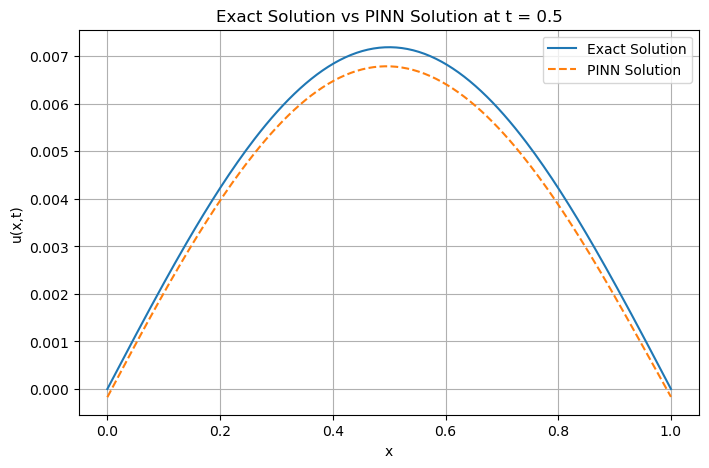

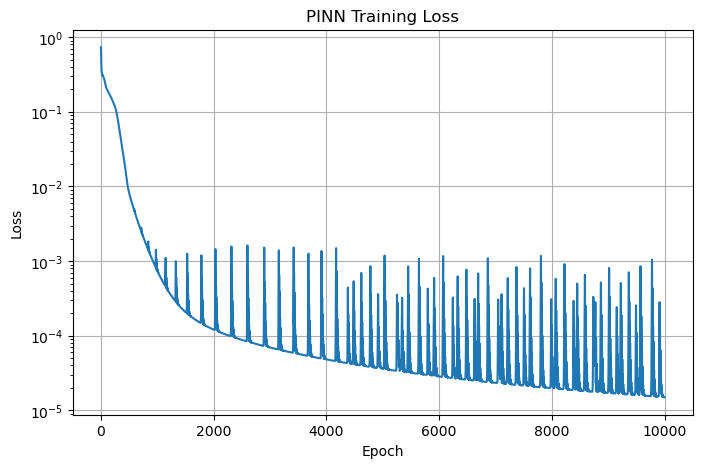

INITIAL TRAINING
Epoch: 0 Loss: 0.96848375
Epoch: 500 Loss: 0.03330931
Epoch: 1000 Loss: 0.00334479
Epoch: 1500 Loss: 0.00078997
Epoch: 2000 Loss: 0.00025285
Epoch: 2500 Loss: 0.00013793
Initial training time: 4.22 seconds

ADAPTIVE SAMPLING
Adaptive points added: 500
Total collocation points: 1500

ADAPTIVE TRAINING
Epoch: 0 Loss: 0.00044215
Epoch: 500 Loss: 0.00024420
Epoch: 1000 Loss: 0.00020030
Epoch: 1500 Loss: 0.00015898
Epoch: 2000 Loss: 0.00012395
Epoch: 2500 Loss: 0.00010157
Adaptive training time: 7.39 seconds

FINAL RESULTS
Maximum Error: 0.001511983573436737
L2 Error: 0.0008012038888409734
Total Collocation Points: 1500


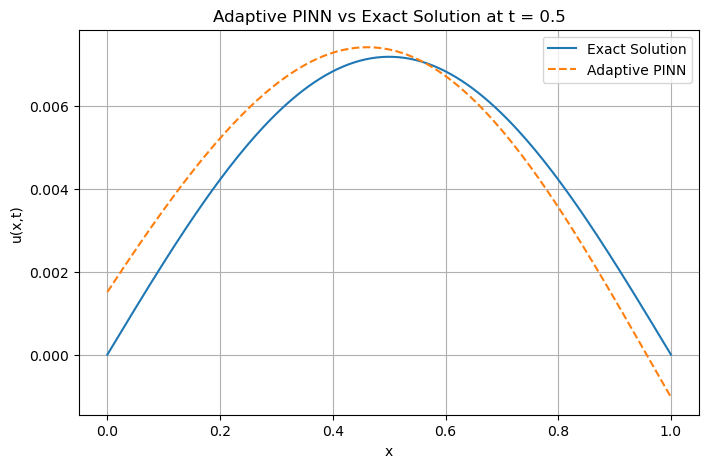

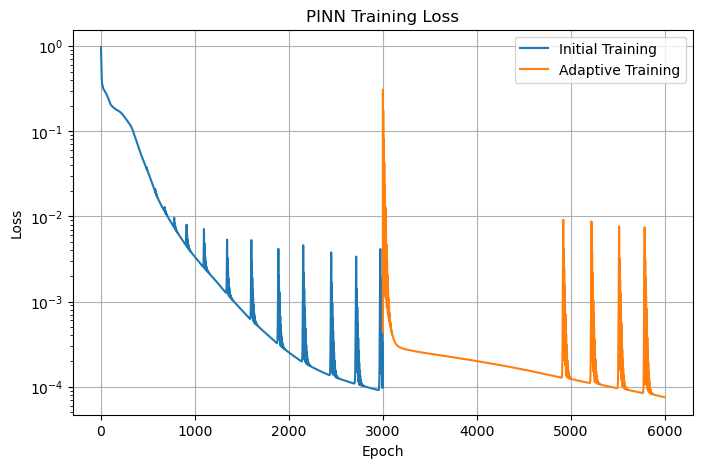

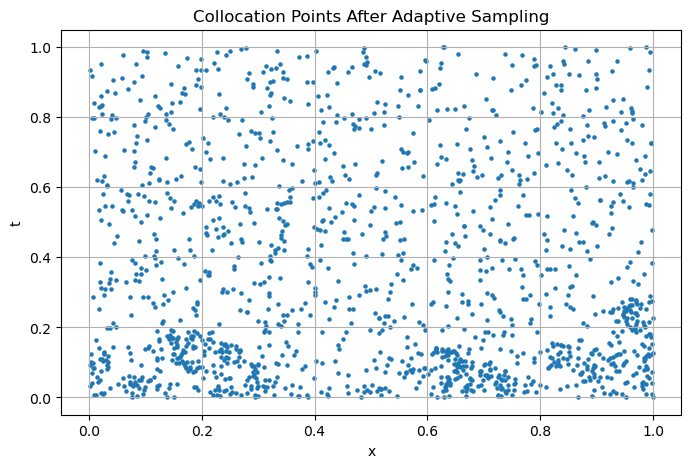

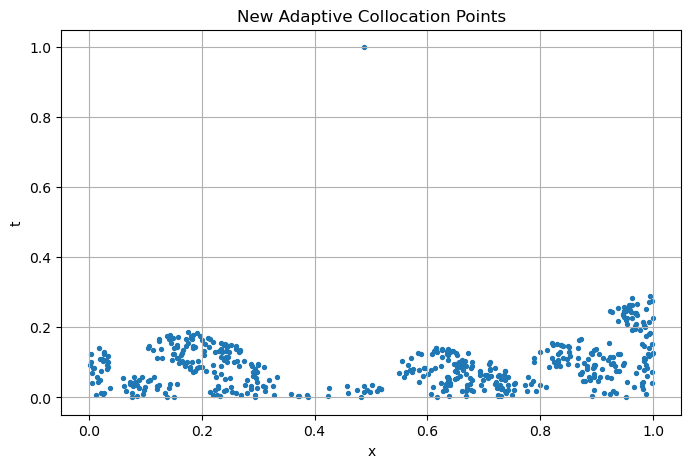

In [6]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# ============================================================
# 1. Neural Network Model
# ============================================================

class PINN(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(2, 32),
            nn.Tanh(),

            nn.Linear(32, 32),
            nn.Tanh(),

            nn.Linear(32, 32),
            nn.Tanh(),

            nn.Linear(32, 1)
        )

    def forward(self, x, t):
        inputs = torch.cat([x, t], dim=1)
        return self.network(inputs)


model = PINN()


# ============================================================
# 2. Collocation Points
# ============================================================

N_f = 1000

x_f = torch.rand(N_f, 1)
t_f = torch.rand(N_f, 1)

x_f.requires_grad = True
t_f.requires_grad = True


# ============================================================
# 3. Initial Condition
#    u(x,0) = sin(pi*x)
# ============================================================

N_ic = 100

x_ic = torch.rand(N_ic, 1)
t_ic = torch.zeros(N_ic, 1)

u_ic = torch.sin(torch.pi * x_ic)


# ============================================================
# 4. Boundary Condition
#    u(0,t) = 0
#    u(1,t) = 0
# ============================================================

N_bc = 100

t_bc = torch.rand(N_bc, 1)

x_left = torch.zeros(N_bc, 1)
x_right = torch.ones(N_bc, 1)


# ============================================================
# 5. PDE Residual
#
#    Heat Equation:
#    u_t = u_xx
#
#    Therefore:
#    Residual = u_t - u_xx
# ============================================================

def pde_residual(model, x, t):

    u = model(x, t)

    # du/dt
    u_t = torch.autograd.grad(
        u,
        t,
        torch.ones_like(u),
        create_graph=True
    )[0]

    # du/dx
    u_x = torch.autograd.grad(
        u,
        x,
        torch.ones_like(u),
        create_graph=True
    )[0]

    # d2u/dx2
    u_xx = torch.autograd.grad(
        u_x,
        x,
        torch.ones_like(u_x),
        create_graph=True
    )[0]

    residual = u_t - u_xx

    return residual


# ============================================================
# 6. Loss Function
# ============================================================

def loss_function():

    # -----------------------------
    # PDE Loss
    # -----------------------------

    residual = pde_residual(
        model,
        x_f,
        t_f
    )

    loss_pde = torch.mean(residual**2)


    # -----------------------------
    # Initial Condition Loss
    # -----------------------------

    u_ic_pred = model(
        x_ic,
        t_ic
    )

    loss_ic = torch.mean(
        (u_ic_pred - u_ic)**2
    )


    # -----------------------------
    # Boundary Condition Loss
    # -----------------------------

    u_left = model(
        x_left,
        t_bc
    )

    u_right = model(
        x_right,
        t_bc
    )

    loss_bc = torch.mean(u_left**2) + \
              torch.mean(u_right**2)


    # -----------------------------
    # Total Loss
    # -----------------------------

    total_loss = (
        loss_pde
        + loss_ic
        + loss_bc
    )

    return (
        total_loss,
        loss_pde,
        loss_ic,
        loss_bc
    )


# ============================================================
# 7. Optimizer
# ============================================================

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)


# ============================================================
# 8. Training
# ============================================================

epochs = 10000

loss_history = []


for epoch in range(epochs):

    optimizer.zero_grad()


    total_loss, loss_pde, loss_ic, loss_bc = \
        loss_function()


    total_loss.backward()

    optimizer.step()


    loss_history.append(
        total_loss.item()
    )


    if epoch % 1000 == 0:

        print(
            f"Epoch: {epoch}, "
            f"Total Loss: {total_loss.item():.6f}, "
            f"PDE Loss: {loss_pde.item():.6f}, "
            f"IC Loss: {loss_ic.item():.6f}, "
            f"BC Loss: {loss_bc.item():.6f}"
        )


# ============================================================
# 9. Test the PINN
# ============================================================

x_test = torch.linspace(
    0,
    1,
    200
).reshape(-1, 1)

t_test = torch.ones_like(x_test) * 0.5


# PINN prediction

with torch.no_grad():

    u_pred = model(
        x_test,
        t_test
    )


# ============================================================
# 10. Exact Solution
#
# u(x,t) = exp(-pi^2*t) sin(pi*x)
# ============================================================

u_exact = torch.exp(
    -torch.pi**2 * t_test
) * torch.sin(
    torch.pi * x_test
)


# ============================================================
# 11. Calculate Error
# ============================================================

error = torch.abs(
    u_pred - u_exact
)

max_error = torch.max(error)

print()
print(
    "Maximum Error:",
    max_error.item()
)


# ============================================================
# 12. Plot Exact vs PINN
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    x_test.numpy(),
    u_exact.numpy(),
    label="Exact Solution"
)

plt.plot(
    x_test.numpy(),
    u_pred.numpy(),
    "--",
    label="PINN Solution"
)

plt.xlabel("x")
plt.ylabel("u(x,t)")

plt.title(
    "Exact Solution vs PINN Solution at t = 0.5"
)

plt.legend()

plt.grid()

plt.show()


# ============================================================
# 13. Plot Training Loss
# ============================================================

plt.figure(figsize=(8, 5))

plt.semilogy(
    loss_history
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title(
    "PINN Training Loss"
)

plt.grid()

plt.show()

import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import time


# =========================================================
# 1. PINN MODEL
# =========================================================

class PINN(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(2, 32),
            nn.Tanh(),

            nn.Linear(32, 32),
            nn.Tanh(),

            nn.Linear(32, 32),
            nn.Tanh(),

            nn.Linear(32, 1)
        )

    def forward(self, x, t):

        inputs = torch.cat([x, t], dim=1)

        return self.network(inputs)


model = PINN()


# =========================================================
# 2. PDE RESIDUAL
#
# Heat equation:
#
#       u_t = u_xx
#
# Therefore:
#
#       Residual = u_t - u_xx
# =========================================================

def pde_residual(model, x, t):

    x = x.clone().detach().requires_grad_(True)
    t = t.clone().detach().requires_grad_(True)

    u = model(x, t)

    u_t = torch.autograd.grad(
        u,
        t,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    u_x = torch.autograd.grad(
        u,
        x,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    u_xx = torch.autograd.grad(
        u_x,
        x,
        grad_outputs=torch.ones_like(u_x),
        create_graph=True
    )[0]

    residual = u_t - u_xx

    return residual


# =========================================================
# 3. INITIAL COLLOCATION POINTS
# =========================================================

N_initial = 1000

x_f = torch.rand(N_initial, 1)
t_f = torch.rand(N_initial, 1)


# =========================================================
# 4. INITIAL CONDITION
#
# u(x,0) = sin(pi*x)
# =========================================================

N_ic = 100

x_ic = torch.rand(N_ic, 1)

t_ic = torch.zeros(N_ic, 1)

u_ic = torch.sin(torch.pi * x_ic)


# =========================================================
# 5. BOUNDARY CONDITIONS
#
# u(0,t) = 0
# u(1,t) = 0
# =========================================================

N_bc = 100

t_bc = torch.rand(N_bc, 1)

x_left = torch.zeros(N_bc, 1)

x_right = torch.ones(N_bc, 1)


# =========================================================
# 6. LOSS FUNCTION
# =========================================================

def loss_function():

    # PDE loss
    residual = pde_residual(
        model,
        x_f,
        t_f
    )

    loss_pde = torch.mean(
        residual ** 2
    )


    # Initial condition loss
    u_ic_pred = model(
        x_ic,
        t_ic
    )

    loss_ic = torch.mean(
        (u_ic_pred - u_ic) ** 2
    )


    # Boundary condition loss
    u_left = model(
        x_left,
        t_bc
    )

    u_right = model(
        x_right,
        t_bc
    )

    loss_bc = (
        torch.mean(u_left ** 2)
        +
        torch.mean(u_right ** 2)
    )


    # Total loss
    total_loss = (
        loss_pde
        +
        loss_ic
        +
        loss_bc
    )

    return total_loss


# =========================================================
# 7. TRAINING FUNCTION
# =========================================================

def train_model(epochs):

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    loss_history = []

    for epoch in range(epochs):

        optimizer.zero_grad()

        loss = loss_function()

        loss.backward()

        optimizer.step()

        loss_history.append(
            loss.item()
        )

        if epoch % 500 == 0:

            print(
                "Epoch:",
                epoch,
                "Loss:",
                f"{loss.item():.8f}"
            )

    return loss_history


# =========================================================
# 8. INITIAL TRAINING
# =========================================================

print("===================================")
print("INITIAL TRAINING")
print("===================================")

start_time = time.time()

loss_initial = train_model(
    epochs=3000
)

initial_time = time.time() - start_time

print(
    "Initial training time:",
    round(initial_time, 2),
    "seconds"
)


# =========================================================
# 9. CREATE CANDIDATE POINTS
#
# These points are used to find regions
# where PDE residual is high.
# =========================================================

N_candidate = 5000

x_candidate = torch.rand(
    N_candidate,
    1
)

t_candidate = torch.rand(
    N_candidate,
    1
)


# =========================================================
# 10. CALCULATE PDE RESIDUAL
# =========================================================

residual_candidate = pde_residual(
    model,
    x_candidate,
    t_candidate
)


residual_value = torch.abs(
    residual_candidate.detach()
)


# =========================================================
# 11. SELECT HIGH-RESIDUAL POINTS
# =========================================================

N_adaptive = 500

values = residual_value.flatten()

top_values, indices = torch.topk(
    values,
    N_adaptive
)


x_new = x_candidate[
    indices
].detach()

t_new = t_candidate[
    indices
].detach()


# =========================================================
# 12. ADD ADAPTIVE POINTS
# =========================================================

x_f = torch.cat(
    [
        x_f,
        x_new
    ],
    dim=0
)

t_f = torch.cat(
    [
        t_f,
        t_new
    ],
    dim=0
)


print()
print("===================================")
print("ADAPTIVE SAMPLING")
print("===================================")

print(
    "Adaptive points added:",
    N_adaptive
)

print(
    "Total collocation points:",
    len(x_f)
)


# =========================================================
# 13. ADAPTIVE RETRAINING
# =========================================================

print()
print("===================================")
print("ADAPTIVE TRAINING")
print("===================================")

start_time = time.time()

loss_adaptive = train_model(
    epochs=3000
)

adaptive_time = time.time() - start_time

print(
    "Adaptive training time:",
    round(adaptive_time, 2),
    "seconds"
)


# =========================================================
# 14. TEST POINTS
# =========================================================

x_test = torch.linspace(
    0,
    1,
    200
).reshape(-1, 1)


t_test = torch.ones_like(
    x_test
) * 0.5


# =========================================================
# 15. PINN PREDICTION
# =========================================================

with torch.no_grad():

    u_pred = model(
        x_test,
        t_test
    )


# =========================================================
# 16. EXACT SOLUTION
#
# u(x,t) = exp(-pi^2*t) sin(pi*x)
# =========================================================

u_exact = (
    torch.exp(
        -torch.pi ** 2 * t_test
    )
    *
    torch.sin(
        torch.pi * x_test
    )
)


# =========================================================
# 17. ERROR CALCULATION
# =========================================================

error = torch.abs(
    u_pred - u_exact
)


max_error = torch.max(
    error
)


L2_error = torch.sqrt(
    torch.mean(
        (u_pred - u_exact) ** 2
    )
)


print()
print("===================================")
print("FINAL RESULTS")
print("===================================")

print(
    "Maximum Error:",
    max_error.item()
)

print(
    "L2 Error:",
    L2_error.item()
)

print(
    "Total Collocation Points:",
    len(x_f)
)


# =========================================================
# 18. EXACT VS PINN SOLUTION
# =========================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    x_test.numpy(),
    u_exact.numpy(),
    label="Exact Solution"
)

plt.plot(
    x_test.numpy(),
    u_pred.numpy(),
    "--",
    label="Adaptive PINN"
)

plt.xlabel("x")

plt.ylabel("u(x,t)")

plt.title(
    "Adaptive PINN vs Exact Solution at t = 0.5"
)

plt.legend()

plt.grid()

plt.show()


# =========================================================
# 19. TRAINING LOSS
# =========================================================

plt.figure(
    figsize=(8, 5)
)

plt.semilogy(
    loss_initial,
    label="Initial Training"
)

plt.semilogy(
    range(
        len(loss_initial),
        len(loss_initial)
        + len(loss_adaptive)
    ),
    loss_adaptive,
    label="Adaptive Training"
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title(
    "PINN Training Loss"
)

plt.legend()

plt.grid()

plt.show()


# =========================================================
# 20. ADAPTIVE COLLOCATION POINTS
# =========================================================

plt.figure(
    figsize=(8, 5)
)

plt.scatter(
    x_f.numpy(),
    t_f.numpy(),
    s=5
)

plt.xlabel("x")

plt.ylabel("t")

plt.title(
    "Collocation Points After Adaptive Sampling"
)

plt.grid()

plt.show()


# =========================================================
# 21. HIGH-RESIDUAL POINTS ONLY
# =========================================================

plt.figure(
    figsize=(8, 5)
)

plt.scatter(
    x_new.numpy(),
    t_new.numpy(),
    s=8
)

plt.xlabel("x")

plt.ylabel("t")

plt.title(
    "New Adaptive Collocation Points"
)

plt.grid()

plt.show()

UNIFORM / RANDOM PINN TRAINING
Epoch: 0 Loss: 0.45477146
Epoch: 500 Loss: 0.01546364
Epoch: 1000 Loss: 0.00270707
Epoch: 1500 Loss: 0.00038208
Epoch: 2000 Loss: 0.00025148
Epoch: 2500 Loss: 0.00018070
Epoch: 3000 Loss: 0.00013336
Epoch: 3500 Loss: 0.00010351
Epoch: 4000 Loss: 0.00008395
Epoch: 4500 Loss: 0.00065113
Epoch: 5000 Loss: 0.00005460
Epoch: 5500 Loss: 0.00294231

Training Time: 14.9 seconds

UNIFORM / RANDOM FINAL RESULTS
Total Collocation Points: 1500
Training Time: 14.9 seconds
Maximum Error: 0.0013245908776298165
L2 Error: 0.0005358353955671191
Mean PDE Residual: 0.0034391439985483885


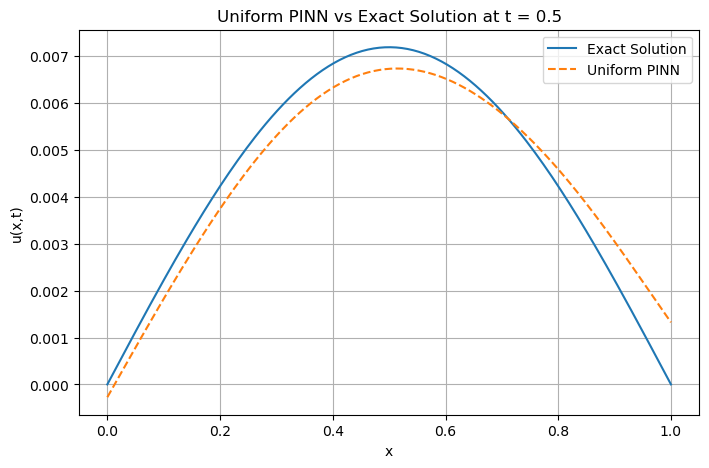

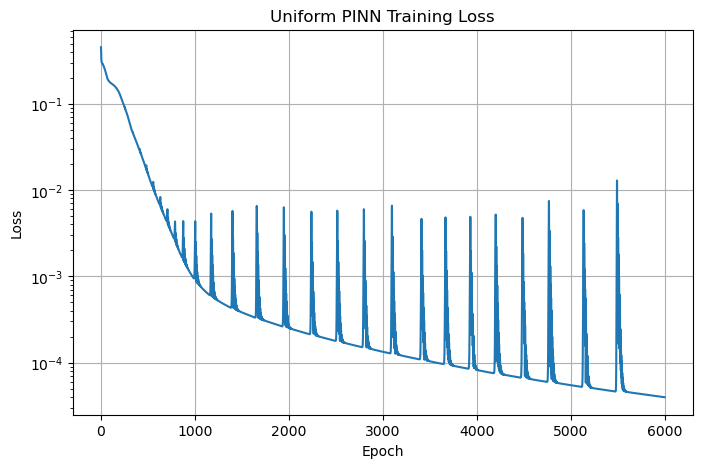

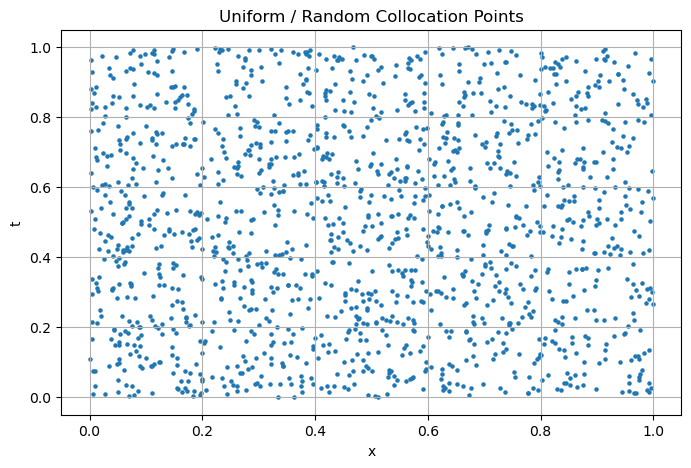

In [7]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import time

# ==========================================
# 1. PINN MODEL
# ==========================================

class PINN(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(2, 32),
            nn.Tanh(),

            nn.Linear(32, 32),
            nn.Tanh(),

            nn.Linear(32, 32),
            nn.Tanh(),

            nn.Linear(32, 1)
        )

    def forward(self, x, t):
        inputs = torch.cat([x, t], dim=1)
        return self.network(inputs)


model = PINN()


# ==========================================
# 2. PDE RESIDUAL
# ==========================================

def pde_residual(model, x, t):

    x = x.clone().detach().requires_grad_(True)
    t = t.clone().detach().requires_grad_(True)

    u = model(x, t)

    u_t = torch.autograd.grad(
        u,
        t,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    u_x = torch.autograd.grad(
        u,
        x,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    u_xx = torch.autograd.grad(
        u_x,
        x,
        grad_outputs=torch.ones_like(u_x),
        create_graph=True
    )[0]

    residual = u_t - u_xx

    return residual


# ==========================================
# 3. UNIFORM / RANDOM COLLOCATION POINTS
# ==========================================

N_f = 1500

x_f = torch.rand(N_f, 1)
t_f = torch.rand(N_f, 1)


# ==========================================
# 4. INITIAL CONDITION
# ==========================================

N_ic = 100

x_ic = torch.rand(N_ic, 1)
t_ic = torch.zeros(N_ic, 1)

u_ic = torch.sin(torch.pi * x_ic)


# ==========================================
# 5. BOUNDARY CONDITIONS
# ==========================================

N_bc = 100

t_bc = torch.rand(N_bc, 1)

x_left = torch.zeros(N_bc, 1)
x_right = torch.ones(N_bc, 1)


# ==========================================
# 6. LOSS FUNCTION
# ==========================================

def loss_function():

    # PDE loss

    residual = pde_residual(
        model,
        x_f,
        t_f
    )

    loss_pde = torch.mean(
        residual ** 2
    )


    # Initial condition loss

    u_ic_pred = model(
        x_ic,
        t_ic
    )

    loss_ic = torch.mean(
        (u_ic_pred - u_ic) ** 2
    )


    # Boundary condition loss

    u_left = model(
        x_left,
        t_bc
    )

    u_right = model(
        x_right,
        t_bc
    )

    loss_bc = (
        torch.mean(u_left ** 2)
        +
        torch.mean(u_right ** 2)
    )


    # Total loss

    total_loss = (
        loss_pde
        +
        loss_ic
        +
        loss_bc
    )

    return total_loss


# ==========================================
# 7. TRAINING
# ==========================================

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 6000

loss_history = []


print("===================================")
print("UNIFORM / RANDOM PINN TRAINING")
print("===================================")

start_time = time.time()


for epoch in range(epochs):

    optimizer.zero_grad()

    loss = loss_function()

    loss.backward()

    optimizer.step()

    loss_history.append(
        loss.item()
    )

    if epoch % 500 == 0:

        print(
            "Epoch:",
            epoch,
            "Loss:",
            f"{loss.item():.8f}"
        )


training_time = time.time() - start_time


print()
print("Training Time:",
      round(training_time, 2),
      "seconds")


# ==========================================
# 8. TEST GRID
# ==========================================

x_test = torch.linspace(
    0,
    1,
    200
).reshape(-1, 1)

t_test = (
    torch.ones_like(x_test)
    * 0.5
)


# ==========================================
# 9. PINN PREDICTION
# ==========================================

with torch.no_grad():

    u_pred = model(
        x_test,
        t_test
    )


# ==========================================
# 10. EXACT SOLUTION
# ==========================================

u_exact = (
    torch.exp(
        -torch.pi ** 2
        * t_test
    )
    *
    torch.sin(
        torch.pi
        * x_test
    )
)


# ==========================================
# 11. ERROR CALCULATION
# ==========================================

error = torch.abs(
    u_pred - u_exact
)


max_error = torch.max(
    error
)


L2_error = torch.sqrt(
    torch.mean(
        (u_pred - u_exact) ** 2
    )
)


# ==========================================
# 12. PDE RESIDUAL
# ==========================================

residual_test = pde_residual(
    model,
    x_test,
    t_test
)

mean_pde_residual = torch.mean(
    torch.abs(
        residual_test
    )
)


# ==========================================
# 13. FINAL RESULTS
# ==========================================

print()
print("===================================")
print("UNIFORM / RANDOM FINAL RESULTS")
print("===================================")

print(
    "Total Collocation Points:",
    N_f
)

print(
    "Training Time:",
    round(training_time, 2),
    "seconds"
)

print(
    "Maximum Error:",
    max_error.item()
)

print(
    "L2 Error:",
    L2_error.item()
)

print(
    "Mean PDE Residual:",
    mean_pde_residual.item()
)


# ==========================================
# 14. SOLUTION PLOT
# ==========================================

plt.figure(figsize=(8, 5))

plt.plot(
    x_test.numpy(),
    u_exact.numpy(),
    label="Exact Solution"
)

plt.plot(
    x_test.numpy(),
    u_pred.numpy(),
    "--",
    label="Uniform PINN"
)

plt.xlabel("x")
plt.ylabel("u(x,t)")

plt.title(
    "Uniform PINN vs Exact Solution at t = 0.5"
)

plt.legend()
plt.grid()

plt.show()


# ==========================================
# 15. LOSS PLOT
# ==========================================

plt.figure(figsize=(8, 5))

plt.semilogy(
    loss_history
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Uniform PINN Training Loss"
)

plt.grid()

plt.show()


# ==========================================
# 16. COLLOCATION POINT PLOT
# ==========================================

plt.figure(figsize=(8, 5))

plt.scatter(
    x_f.numpy(),
    t_f.numpy(),
    s=5
)

plt.xlabel("x")
plt.ylabel("t")

plt.title(
    "Uniform / Random Collocation Points"
)

plt.grid()

plt.show()


RUN 1 / 5
SEED = 1

----- UNIFORM -----
L2 Error: 0.0007804841152392328
Maximum Error: 0.0010921620996668935
Mean PDE Residual: 0.0031303600408136845
Training Time: 14.83 seconds

----- ADAPTIVE -----
L2 Error: 0.0010029934346675873
Maximum Error: 0.0016218045493587852
Mean PDE Residual: 0.004097724333405495
Training Time: 11.47 seconds

RUN 2 / 5
SEED = 2

----- UNIFORM -----
L2 Error: 0.00028848141664639115
Maximum Error: 0.0005467012524604797
Mean PDE Residual: 0.003193094627931714
Training Time: 15.04 seconds

----- ADAPTIVE -----
L2 Error: 0.0002277426392538473
Maximum Error: 0.0005494796787388623
Mean PDE Residual: 0.0037007618229836226
Training Time: 11.34 seconds

RUN 3 / 5
SEED = 3

----- UNIFORM -----
L2 Error: 0.0012157517485320568
Maximum Error: 0.0013703731819987297
Mean PDE Residual: 0.003632914973422885
Training Time: 14.97 seconds

----- ADAPTIVE -----
L2 Error: 0.0015820229891687632
Maximum Error: 0.0018850553315132856
Mean PDE Residual: 0.005557709839195013
Training 

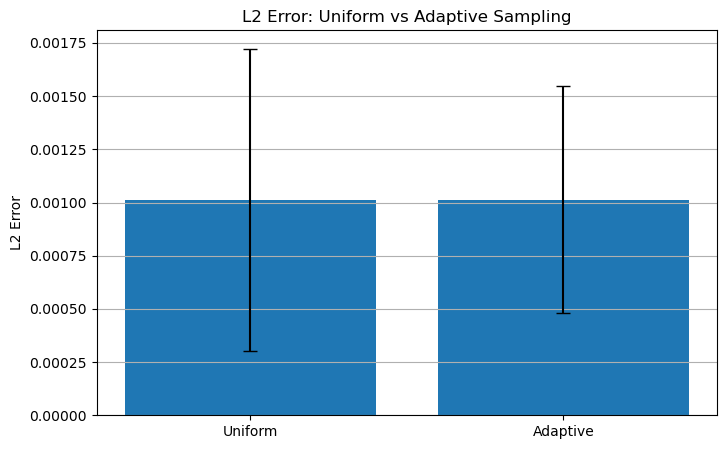

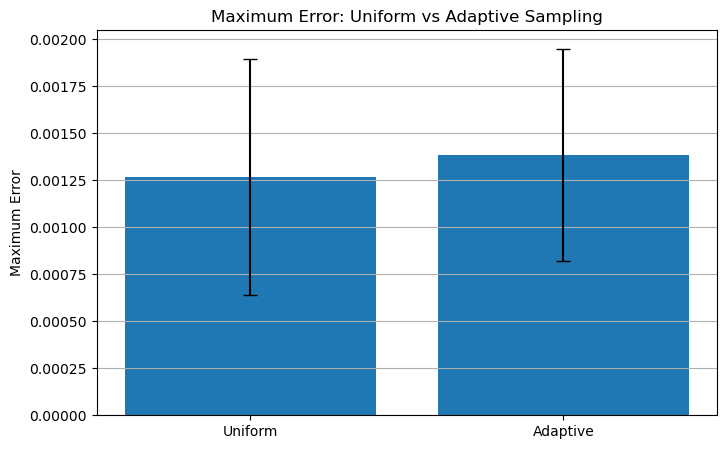

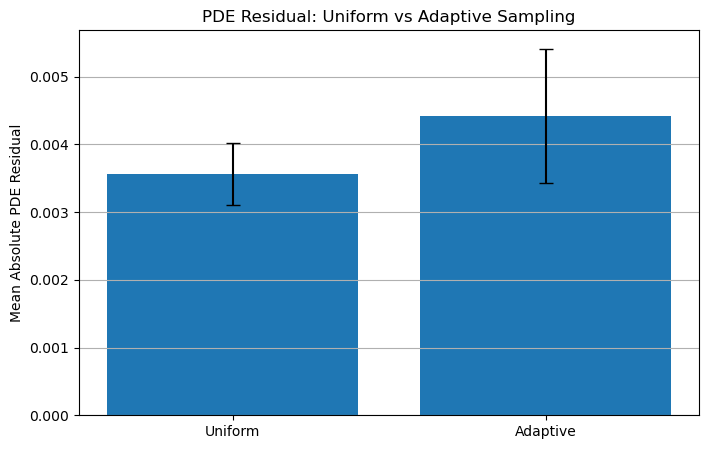

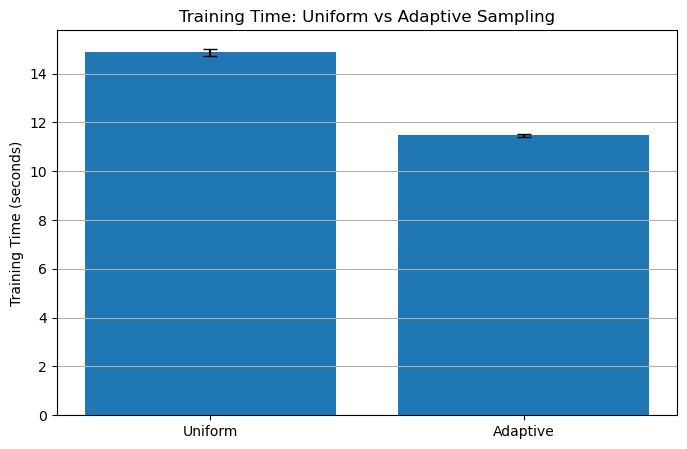

In [8]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import time
import numpy as np


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

def set_seed(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)


# ============================================================
# 2. PINN MODEL
# ============================================================

class PINN(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(2, 32),
            nn.Tanh(),

            nn.Linear(32, 32),
            nn.Tanh(),

            nn.Linear(32, 32),
            nn.Tanh(),

            nn.Linear(32, 1)
        )

    def forward(self, x, t):

        inputs = torch.cat([x, t], dim=1)

        return self.network(inputs)


# ============================================================
# 3. PDE RESIDUAL
# PDE: u_t = u_xx
# ============================================================

def pde_residual(model, x, t):

    x = x.clone().detach().requires_grad_(True)
    t = t.clone().detach().requires_grad_(True)

    u = model(x, t)

    u_t = torch.autograd.grad(
        u,
        t,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    u_x = torch.autograd.grad(
        u,
        x,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    u_xx = torch.autograd.grad(
        u_x,
        x,
        grad_outputs=torch.ones_like(u_x),
        create_graph=True
    )[0]

    return u_t - u_xx


# ============================================================
# 4. LOSS FUNCTION
# ============================================================

def calculate_loss(
    model,
    x_f,
    t_f,
    x_ic,
    t_ic,
    u_ic,
    x_left,
    x_right,
    t_bc
):

    # PDE loss
    residual = pde_residual(
        model,
        x_f,
        t_f
    )

    loss_pde = torch.mean(
        residual ** 2
    )


    # Initial condition loss
    u_ic_pred = model(
        x_ic,
        t_ic
    )

    loss_ic = torch.mean(
        (u_ic_pred - u_ic) ** 2
    )


    # Boundary condition loss
    u_left = model(
        x_left,
        t_bc
    )

    u_right = model(
        x_right,
        t_bc
    )

    loss_bc = (
        torch.mean(u_left ** 2)
        +
        torch.mean(u_right ** 2)
    )


    total_loss = (
        loss_pde
        +
        loss_ic
        +
        loss_bc
    )

    return total_loss


# ============================================================
# 5. TRAINING FUNCTION
# ============================================================

def train_model(
    model,
    x_f,
    t_f,
    x_ic,
    t_ic,
    u_ic,
    x_left,
    x_right,
    t_bc,
    epochs
):

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    loss_history = []

    start_time = time.time()


    for epoch in range(epochs):

        optimizer.zero_grad()

        loss = calculate_loss(
            model,
            x_f,
            t_f,
            x_ic,
            t_ic,
            u_ic,
            x_left,
            x_right,
            t_bc
        )

        loss.backward()

        optimizer.step()

        loss_history.append(
            loss.item()
        )


    training_time = (
        time.time() - start_time
    )

    return loss_history, training_time


# ============================================================
# 6. TEST DATA
# SAME TEST DATA FOR BOTH METHODS
# ============================================================

x_test = torch.linspace(
    0,
    1,
    200
).reshape(-1, 1)

t_test = (
    torch.ones_like(x_test)
    * 0.5
)


# Exact solution
u_exact = (
    torch.exp(
        -torch.pi ** 2 * t_test
    )
    *
    torch.sin(
        torch.pi * x_test
    )
)


# Fixed PDE residual evaluation points
# These are NOT training points

set_seed(999)

N_residual_test = 2000

x_res_test = torch.rand(
    N_residual_test,
    1
)

t_res_test = torch.rand(
    N_residual_test,
    1
)


# ============================================================
# 7. EXPERIMENT SETTINGS
# ============================================================

N_initial = 1000

N_adaptive = 500

N_uniform = 1500

N_candidate = 5000

N_ic = 100

N_bc = 100

initial_epochs = 3000

adaptive_epochs = 3000

uniform_epochs = 6000

seeds = [1, 2, 3, 4, 5]


# ============================================================
# 8. STORAGE
# ============================================================

uniform_results = []

adaptive_results = []

uniform_losses = []

adaptive_losses = []


# ============================================================
# 9. MAIN EXPERIMENT
# ============================================================

for run, seed in enumerate(seeds):

    print()
    print("================================================")
    print("RUN", run + 1, "/ 5")
    print("SEED =", seed)
    print("================================================")


    # --------------------------------------------------------
    # COMMON INITIAL / BOUNDARY DATA
    # --------------------------------------------------------

    set_seed(seed)

    x_ic = torch.rand(
        N_ic,
        1
    )

    t_ic = torch.zeros(
        N_ic,
        1
    )

    u_ic = torch.sin(
        torch.pi * x_ic
    )


    t_bc = torch.rand(
        N_bc,
        1
    )

    x_left = torch.zeros(
        N_bc,
        1
    )

    x_right = torch.ones(
        N_bc,
        1
    )


    # ========================================================
    # UNIFORM METHOD
    # ========================================================

    print()
    print("----- UNIFORM -----")


    set_seed(seed + 100)

    uniform_model = PINN()


    x_f_uniform = torch.rand(
        N_uniform,
        1
    )

    t_f_uniform = torch.rand(
        N_uniform,
        1
    )


    loss_uniform, time_uniform = train_model(
        uniform_model,
        x_f_uniform,
        t_f_uniform,
        x_ic,
        t_ic,
        u_ic,
        x_left,
        x_right,
        t_bc,
        uniform_epochs
    )


    # Prediction
    with torch.no_grad():

        u_pred_uniform = uniform_model(
            x_test,
            t_test
        )


    error_uniform = torch.abs(
        u_pred_uniform - u_exact
    )


    max_error_uniform = torch.max(
        error_uniform
    ).item()


    L2_uniform = torch.sqrt(
        torch.mean(
            (u_pred_uniform - u_exact) ** 2
        )
    ).item()


    # Fixed PDE residual
    residual_uniform = pde_residual(
        uniform_model,
        x_res_test,
        t_res_test
    )

    mean_residual_uniform = torch.mean(
        torch.abs(
            residual_uniform
        )
    ).item()


    uniform_results.append([
        L2_uniform,
        max_error_uniform,
        mean_residual_uniform,
        time_uniform
    ])


    uniform_losses.append(
        loss_uniform
    )


    print(
        "L2 Error:",
        L2_uniform
    )

    print(
        "Maximum Error:",
        max_error_uniform
    )

    print(
        "Mean PDE Residual:",
        mean_residual_uniform
    )

    print(
        "Training Time:",
        round(time_uniform, 2),
        "seconds"
    )


    # ========================================================
    # ADAPTIVE METHOD
    # ========================================================

    print()
    print("----- ADAPTIVE -----")


    set_seed(seed + 100)

    adaptive_model = PINN()


    # Initial 1000 points

    x_f_adaptive = torch.rand(
        N_initial,
        1
    )

    t_f_adaptive = torch.rand(
        N_initial,
        1
    )


    # --------------------------------------------------------
    # INITIAL TRAINING
    # --------------------------------------------------------

    loss_initial, time_initial = train_model(
        adaptive_model,
        x_f_adaptive,
        t_f_adaptive,
        x_ic,
        t_ic,
        u_ic,
        x_left,
        x_right,
        t_bc,
        initial_epochs
    )


    # --------------------------------------------------------
    # GENERATE CANDIDATE POINTS
    # --------------------------------------------------------

    set_seed(seed + 200)

    x_candidate = torch.rand(
        N_candidate,
        1
    )

    t_candidate = torch.rand(
        N_candidate,
        1
    )


    # Calculate residual
    residual_candidate = pde_residual(
        adaptive_model,
        x_candidate,
        t_candidate
    )


    residual_value = torch.abs(
        residual_candidate.detach()
    ).flatten()


    # Select points with highest residual
    _, indices = torch.topk(
        residual_value,
        N_adaptive
    )


    x_new = x_candidate[
        indices
    ].detach()

    t_new = t_candidate[
        indices
    ].detach()


    # Add adaptive points
    x_f_adaptive = torch.cat(
        [
            x_f_adaptive,
            x_new
        ],
        dim=0
    )

    t_f_adaptive = torch.cat(
        [
            t_f_adaptive,
            t_new
        ],
        dim=0
    )


    # --------------------------------------------------------
    # ADAPTIVE TRAINING
    # --------------------------------------------------------

    loss_adaptive, time_adaptive = train_model(
        adaptive_model,
        x_f_adaptive,
        t_f_adaptive,
        x_ic,
        t_ic,
        u_ic,
        x_left,
        x_right,
        t_bc,
        adaptive_epochs
    )


    total_adaptive_time = (
        time_initial
        +
        time_adaptive
    )


    # --------------------------------------------------------
    # PREDICTION
    # --------------------------------------------------------

    with torch.no_grad():

        u_pred_adaptive = adaptive_model(
            x_test,
            t_test
        )


    error_adaptive = torch.abs(
        u_pred_adaptive - u_exact
    )


    max_error_adaptive = torch.max(
        error_adaptive
    ).item()


    L2_adaptive = torch.sqrt(
        torch.mean(
            (u_pred_adaptive - u_exact) ** 2
        )
    ).item()


    # --------------------------------------------------------
    # FIXED PDE RESIDUAL
    # --------------------------------------------------------

    residual_adaptive = pde_residual(
        adaptive_model,
        x_res_test,
        t_res_test
    )


    mean_residual_adaptive = torch.mean(
        torch.abs(
            residual_adaptive
        )
    ).item()


    adaptive_results.append([
        L2_adaptive,
        max_error_adaptive,
        mean_residual_adaptive,
        total_adaptive_time
    ])


    adaptive_losses.append(
        loss_initial + loss_adaptive
    )


    print(
        "L2 Error:",
        L2_adaptive
    )

    print(
        "Maximum Error:",
        max_error_adaptive
    )

    print(
        "Mean PDE Residual:",
        mean_residual_adaptive
    )

    print(
        "Training Time:",
        round(total_adaptive_time, 2),
        "seconds"
    )


# ============================================================
# 10. CONVERT RESULTS TO NUMPY
# ============================================================

uniform_results = np.array(
    uniform_results
)

adaptive_results = np.array(
    adaptive_results
)


# ============================================================
# 11. MEAN AND STANDARD DEVIATION
# ============================================================

uniform_mean = np.mean(
    uniform_results,
    axis=0
)

uniform_std = np.std(
    uniform_results,
    axis=0,
    ddof=1
)


adaptive_mean = np.mean(
    adaptive_results,
    axis=0
)

adaptive_std = np.std(
    adaptive_results,
    axis=0,
    ddof=1
)


# ============================================================
# 12. FINAL TABLE
# ============================================================

print()
print()
print("========================================================")
print("              FINAL 5-RUN COMPARISON")
print("========================================================")

print()

print(
    "Metric                  Uniform             Adaptive"
)

print(
    "--------------------------------------------------------"
)

print(
    f"L2 Error        "
    f"{uniform_mean[0]:.6f} ± {uniform_std[0]:.6f}    "
    f"{adaptive_mean[0]:.6f} ± {adaptive_std[0]:.6f}"
)

print(
    f"Max Error       "
    f"{uniform_mean[1]:.6f} ± {uniform_std[1]:.6f}    "
    f"{adaptive_mean[1]:.6f} ± {adaptive_std[1]:.6f}"
)

print(
    f"PDE Residual    "
    f"{uniform_mean[2]:.6f} ± {uniform_std[2]:.6f}    "
    f"{adaptive_mean[2]:.6f} ± {adaptive_std[2]:.6f}"
)

print(
    f"Time (s)        "
    f"{uniform_mean[3]:.2f} ± {uniform_std[3]:.2f}      "
    f"{adaptive_mean[3]:.2f} ± {adaptive_std[3]:.2f}"
)

print(
    "========================================================"
)


# ============================================================
# 13. INDIVIDUAL RUN RESULTS
# ============================================================

print()
print("INDIVIDUAL RUN RESULTS")
print()

for i in range(5):

    print(
        f"Run {i+1}: "
        f"Uniform L2 = {uniform_results[i,0]:.6f}, "
        f"Adaptive L2 = {adaptive_results[i,0]:.6f}"
    )


# ============================================================
# 14. L2 ERROR COMPARISON
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    ["Uniform", "Adaptive"],
    [uniform_mean[0], adaptive_mean[0]],
    yerr=[
        uniform_std[0],
        adaptive_std[0]
    ],
    capsize=5
)

plt.ylabel("L2 Error")

plt.title(
    "L2 Error: Uniform vs Adaptive Sampling"
)

plt.grid(
    axis="y"
)

plt.show()


# ============================================================
# 15. MAXIMUM ERROR COMPARISON
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    ["Uniform", "Adaptive"],
    [uniform_mean[1], adaptive_mean[1]],
    yerr=[
        uniform_std[1],
        adaptive_std[1]
    ],
    capsize=5
)

plt.ylabel("Maximum Error")

plt.title(
    "Maximum Error: Uniform vs Adaptive Sampling"
)

plt.grid(
    axis="y"
)

plt.show()


# ============================================================
# 16. PDE RESIDUAL COMPARISON
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    ["Uniform", "Adaptive"],
    [uniform_mean[2], adaptive_mean[2]],
    yerr=[
        uniform_std[2],
        adaptive_std[2]
    ],
    capsize=5
)

plt.ylabel("Mean Absolute PDE Residual")

plt.title(
    "PDE Residual: Uniform vs Adaptive Sampling"
)

plt.grid(
    axis="y"
)

plt.show()


# ============================================================
# 17. TRAINING TIME COMPARISON
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    ["Uniform", "Adaptive"],
    [uniform_mean[3], adaptive_mean[3]],
    yerr=[
        uniform_std[3],
        adaptive_std[3]
    ],
    capsize=5
)

plt.ylabel("Training Time (seconds)")

plt.title(
    "Training Time: Uniform vs Adaptive Sampling"
)

plt.grid(
    axis="y"
)

plt.show()